In [4]:
import numpy as np

In [5]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [6]:
df=sns.load_dataset('titanic')

In [7]:
df.head(5)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [8]:
# Dropping out irrelveant columns

In [9]:
df=df.drop(columns=['embark_town','deck','class','who','alive'])

In [10]:
df.shape

(891, 10)

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   survived    891 non-null    int64  
 1   pclass      891 non-null    int64  
 2   sex         891 non-null    str    
 3   age         714 non-null    float64
 4   sibsp       891 non-null    int64  
 5   parch       891 non-null    int64  
 6   fare        891 non-null    float64
 7   embarked    889 non-null    str    
 8   adult_male  891 non-null    bool   
 9   alone       891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(2)
memory usage: 57.6 KB


In [12]:
df.isnull().sum()

survived        0
pclass          0
sex             0
age           177
sibsp           0
parch           0
fare            0
embarked        2
adult_male      0
alone           0
dtype: int64

In [13]:
df['age'].median()

np.float64(28.0)

In [14]:
df['age']=df['age'].fillna(df['age'].median())

In [15]:
df['embarked'].value_counts()

embarked
S    644
C    168
Q     77
Name: count, dtype: int64

In [16]:
df[['embarked']]=df[['embarked']].ffill()

In [17]:
df.isnull().sum()

survived      0
pclass        0
sex           0
age           0
sibsp         0
parch         0
fare          0
embarked      0
adult_male    0
alone         0
dtype: int64

In [18]:
df=df.drop_duplicates()

In [19]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,775.000000,775.000000,775.000000,775.000000,775.000000,775.000000
mean,0.412903,2.246452,29.581187,0.529032,0.420645,34.878403
std,0.492674,0.853574,13.766359,0.990326,0.840565,52.408474
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,1.000000,21.000000,0.000000,0.000000,8.050000
50%,0.000000,3.000000,28.000000,0.000000,0.000000,15.900000
75%,1.000000,3.000000,36.000000,1.000000,1.000000,34.197900
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


# EDA

pclass


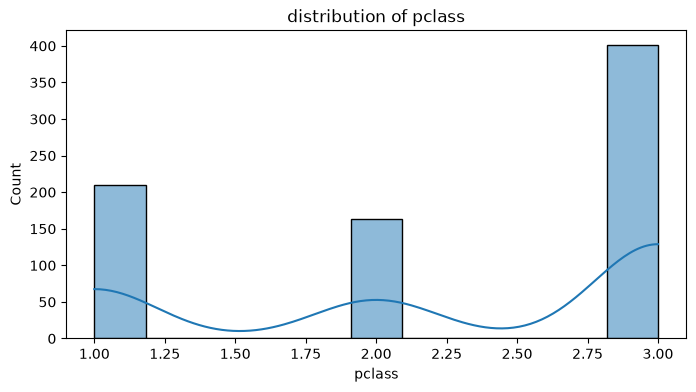

age


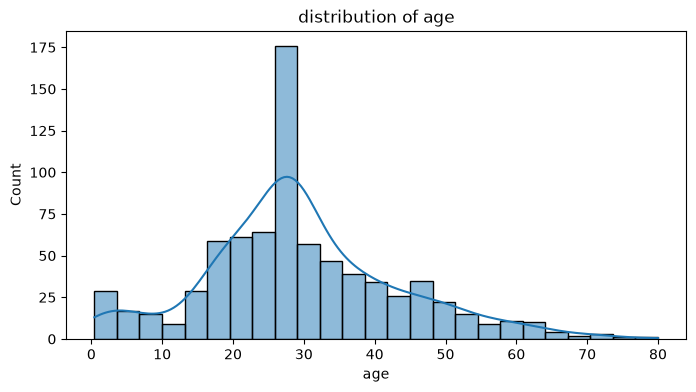

fare


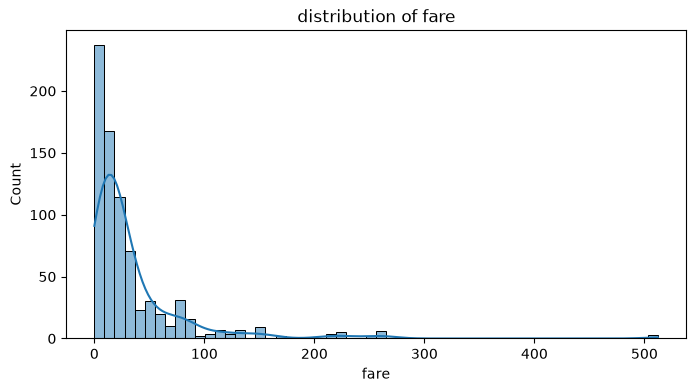

parch


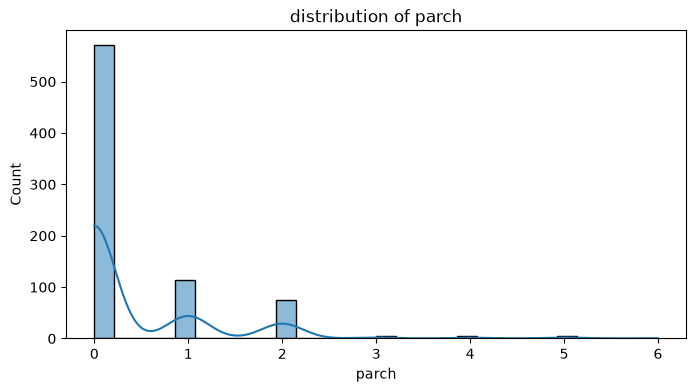

sibsp


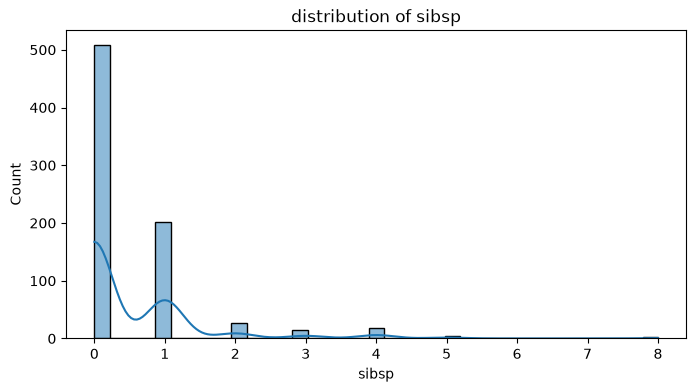

survived


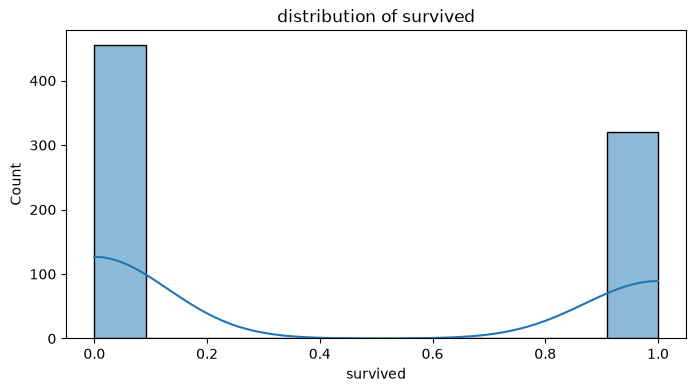

In [20]:
num_cols=('pclass','age','fare','parch','sibsp','survived')
for col in num_cols:
    print(col)
    plt.figure(figsize=(8,4))
    sns.histplot(df[col],kde=True)
    plt.title(f"distribution of {col}")
    plt.show()


In [21]:
# Outlier Detection

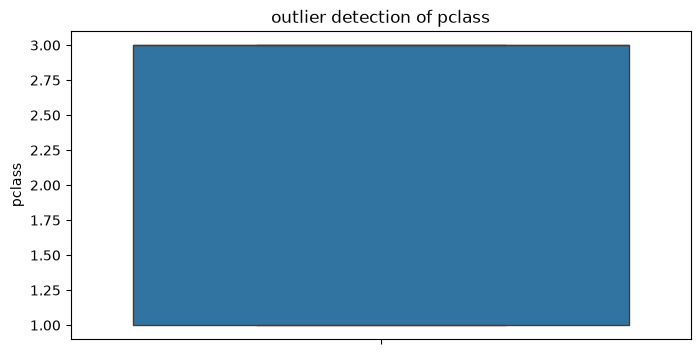

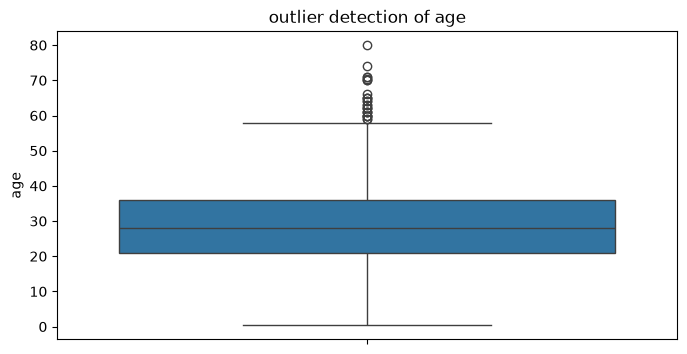

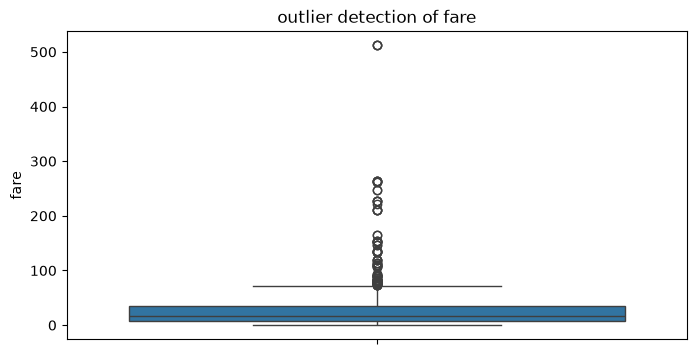

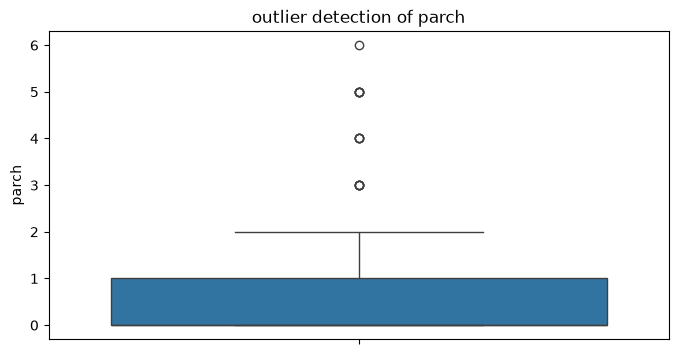

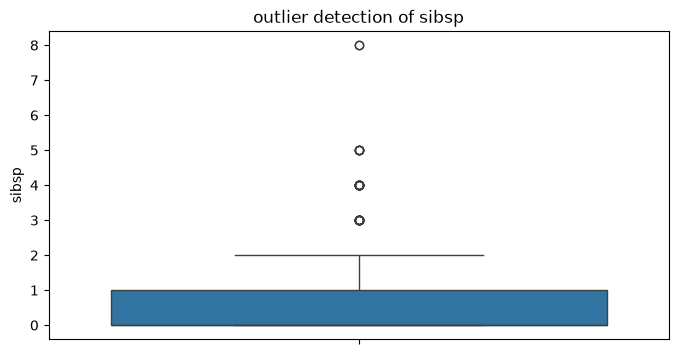

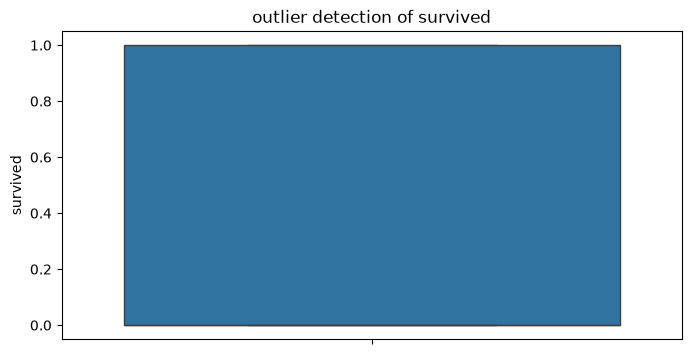

In [22]:
for col in num_cols:
    plt.figure(figsize=(8,4))
    sns.boxplot(df[col])
    plt.title(f"outlier detection of {col}")
    plt.show()

In [23]:
# Handle Outliers

In [24]:
def cap_outliers(df,col):
    Q1=df[col].quantile(0.25)
    Q3=df[col].quantile(0.75)
    IQR=Q3-Q1
    lower=Q1-1.5*IQR
    upper=Q3+1.5*IQR
    df[col]=df[col].clip(lower=lower,upper=upper)
    return df
for col in ['pclass','age','fare','parch','sibsp','survived']:
    df=cap_outliers(df,col)
print(df.shape)
    

(775, 10)


In [25]:
# Now check outlier handle or not

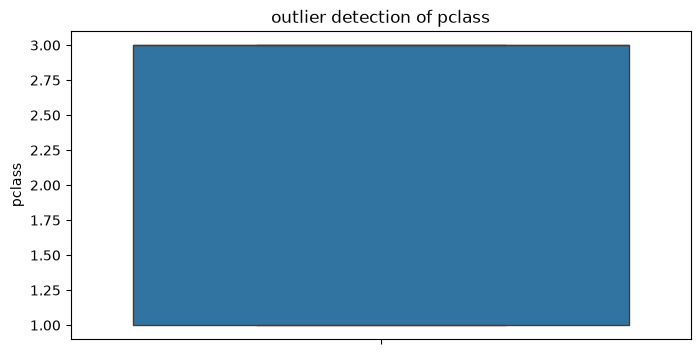

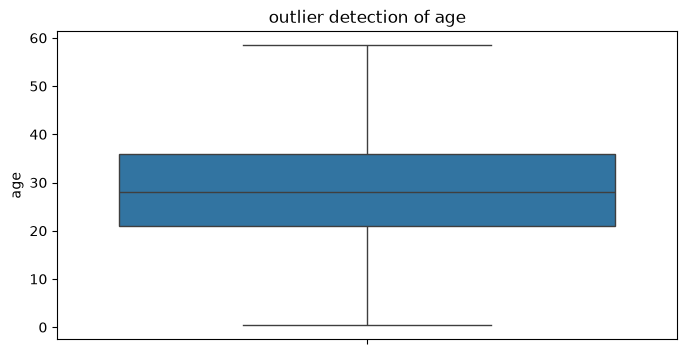

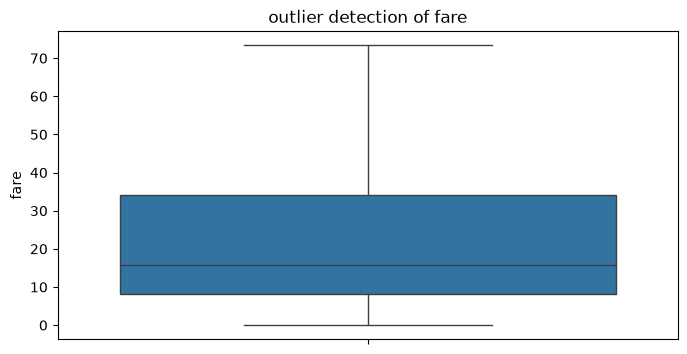

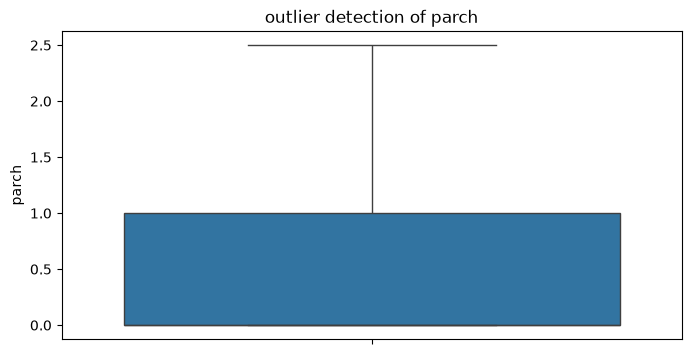

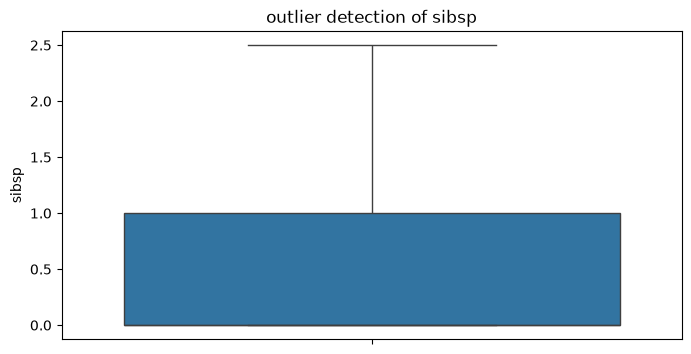

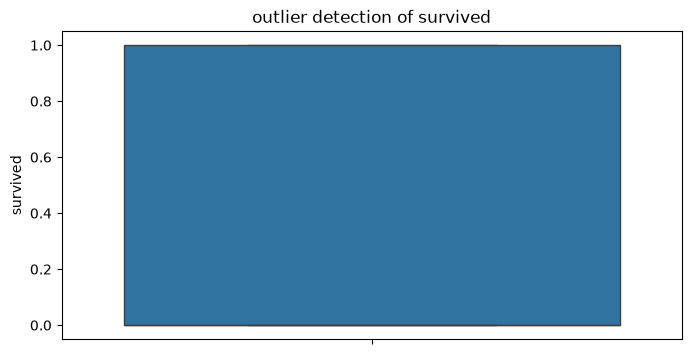

In [26]:
for col in num_cols:
    plt.figure(figsize=(8,4))
    sns.boxplot(df[col])
    plt.title(f"outlier detection of {col}")
    plt.show()

In [27]:
df.head(5)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,adult_male,alone
0,0,3,male,22.0,1.0,0.0,7.2500,S,True,False
1,1,1,female,38.0,1.0,0.0,71.2833,C,False,False
2,1,3,female,26.0,0.0,0.0,7.9250,S,False,True
3,1,1,female,35.0,1.0,0.0,53.1000,S,False,False
4,0,3,male,35.0,0.0,0.0,8.0500,S,True,True


In [28]:
df['parch'].value_counts()

parch
0.0    571
1.0    114
2.0     75
2.5     15
Name: count, dtype: int64

In [29]:
df['survived'].value_counts()

survived
0    455
1    320
Name: count, dtype: int64

# Encoding

In [30]:
# Encode the sex with binnary maping
df['sex']=df['sex'].map({"male":0,"female":1})

In [31]:
df.head(5)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,adult_male,alone
0,0,3,0,22.0,1.0,0.0,7.2500,S,True,False
1,1,1,1,38.0,1.0,0.0,71.2833,C,False,False
2,1,3,1,26.0,0.0,0.0,7.9250,S,False,True
3,1,1,1,35.0,1.0,0.0,53.1000,S,False,False
4,0,3,0,35.0,0.0,0.0,8.0500,S,True,True


In [32]:
# One-hot encoder
from sklearn.preprocessing import OneHotEncoder
ohe=OneHotEncoder()
ohe_encoder=ohe.fit_transform(df[['embarked']])

In [33]:
ohe_encoder.toarray()[:5]

array([[0., 0., 1.],
       [1., 0., 0.],
       [0., 0., 1.],
       [0., 0., 1.],
       [0., 0., 1.]])

In [34]:
encoded_df = pd.DataFrame(
    ohe_encoder.toarray(),                            
    columns=ohe.get_feature_names_out(['embarked']), 
    index=df.index                                    
)

In [35]:
df = pd.concat([df.drop(columns='embarked'), encoded_df], axis=1)

In [36]:
df.head(4)

,survived,pclass,sex,age,sibsp,parch,fare,adult_male,alone,embarked_C,embarked_Q,embarked_S
0,0,3,0,22.0,1.0,0.0,7.2500,True,False,0.0,0.0,1.0
1,1,1,1,38.0,1.0,0.0,71.2833,False,False,1.0,0.0,0.0
2,1,3,1,26.0,0.0,0.0,7.9250,False,True,0.0,0.0,1.0
3,1,1,1,35.0,1.0,0.0,53.1000,False,False,0.0,0.0,1.0


In [37]:
df['adult_male']=df['adult_male'].astype(int)

In [38]:
df['alone']=df['alone'].astype(int)

In [39]:
df.head(4)

,survived,pclass,sex,age,sibsp,parch,fare,adult_male,alone,embarked_C,embarked_Q,embarked_S
0,0,3,0,22.0,1.0,0.0,7.2500,1,0,0.0,0.0,1.0
1,1,1,1,38.0,1.0,0.0,71.2833,0,0,1.0,0.0,0.0
2,1,3,1,26.0,0.0,0.0,7.9250,0,1,0.0,0.0,1.0
3,1,1,1,35.0,1.0,0.0,53.1000,0,0,0.0,0.0,1.0


# Divide into features and Tagert columns

In [40]:
X=df.drop(columns=['survived'])
y=df['survived']

# Train Test Split

In [41]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split( X,y, test_size=0.2,random_state=42)

# Scaling 

In [42]:
from sklearn.preprocessing  import StandardScaler
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)

In [43]:
X_scaled[:5]

array([[ 0.8833855 , -0.77753126, -0.55768253,  0.7661268 , -0.54808761,
        -0.846218  ,  0.86569952, -1.13705735, -0.50201532, -0.28705789,
         0.6196197 ],
       [-1.46121642,  1.28612192,  0.65415665,  0.7661268 , -0.54808761,
         1.95509243, -1.15513521, -1.13705735,  1.99197106, -0.28705789,
        -1.61389317],
       [ 0.8833855 ,  1.28612192, -0.25472273, -0.63919455, -0.54808761,
        -0.81668829, -1.15513521,  0.87946312, -0.50201532, -0.28705789,
         0.6196197 ],
       [-1.46121642,  1.28612192,  0.42693681,  0.7661268 , -0.54808761,
         1.15961464, -1.15513521, -1.13705735, -0.50201532, -0.28705789,
         0.6196197 ],
       [ 0.8833855 , -0.77753126,  0.42693681, -0.63919455, -0.54808761,
        -0.81121983,  0.86569952,  0.87946312, -0.50201532, -0.28705789,
         0.6196197 ]])

# Model Selection

In [44]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier


In [45]:
models={
    "DTC":DecisionTreeClassifier(),
    "RFC":RandomForestClassifier()
}

In [46]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

# Training and model evaulation

In [47]:
for name,model  in models.items():
    model.fit(X_train,y_train)
    y_pred=model.predict(X_test)
    print(f" model:{name}\t accuracy_score{accuracy_score(y_test,y_pred)*100}")

 model:DTC	 accuracy_score70.96774193548387
 model:RFC	 accuracy_score74.19354838709677
